# Import Library

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math

# Import Dataset

In [60]:
df = pd.read_csv('./ncr_ride_bookings.csv')
df

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149995,2024-11-11,19:34:01,"""CNR6500631""",Completed,"""CID4337371""",Go Mini,MG Road,Ghitorni,10.2,44.4,...,NaN,NaN,NaN,NaN,NaN,475.0,40.08,3.7,4.1,Uber Wallet
149996,2024-11-24,15:55:09,"""CNR2468611""",Completed,"""CID2325623""",Go Mini,Golf Course Road,Akshardham,5.1,30.8,...,NaN,NaN,NaN,NaN,NaN,1093.0,21.31,4.8,5.0,UPI
149997,2024-09-18,10:55:15,"""CNR6358306""",Completed,"""CID9925486""",Go Sedan,Satguru Ram Singh Marg,Jor Bagh,2.7,23.4,...,NaN,NaN,NaN,NaN,NaN,852.0,15.93,3.9,4.4,Cash
149998,2024-10-05,07:53:34,"""CNR3030099""",Completed,"""CID9415487""",Auto,Ghaziabad,Saidulajab,6.9,39.6,...,NaN,NaN,NaN,NaN,NaN,333.0,45.54,4.1,3.7,UPI


# Data Understanding

In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  str    
 1   Time                               150000 non-null  str    
 2   Booking ID                         150000 non-null  str    
 3   Booking Status                     150000 non-null  str    
 4   Customer ID                        150000 non-null  str    
 5   Vehicle Type                       150000 non-null  str    
 6   Pickup Location                    150000 non-null  str    
 7   Drop Location                      150000 non-null  str    
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  10500 non-null 

In [62]:
df.describe()

,Avg VTAT,Avg CTAT,Cancelled Rides by Customer,Cancelled Rides by Driver,Incomplete Rides,Booking Value,Ride Distance,Driver Ratings,Customer Rating
count,139500.000000,102000.000000,10500.0,27000.0,9000.0,102000.000000,102000.000000,93000.000000,93000.000000
mean,8.456352,29.149636,1.0,1.0,1.0,508.295912,24.637012,4.230992,4.404584
std,3.773564,8.902577,0.0,0.0,0.0,395.805774,14.002138,0.436871,0.437819
min,2.000000,10.000000,1.0,1.0,1.0,50.000000,1.000000,3.000000,3.000000
25%,5.300000,21.600000,1.0,1.0,1.0,234.000000,12.460000,4.100000,4.200000
50%,8.300000,28.800000,1.0,1.0,1.0,414.000000,23.720000,4.300000,4.500000
75%,11.300000,36.800000,1.0,1.0,1.0,689.000000,36.820000,4.600000,4.800000
max,20.000000,45.000000,1.0,1.0,1.0,4277.000000,50.000000,5.000000,5.000000


In [63]:
for i in df.columns:
    print(f"{i} : {round((1 - (df[i].count() / df.shape[0])) * 100, 2)}% null")

Date : 0.0% null
Time : 0.0% null
Booking ID : 0.0% null
Booking Status : 0.0% null
Customer ID : 0.0% null
Vehicle Type : 0.0% null
Pickup Location : 0.0% null
Drop Location : 0.0% null
Avg VTAT : 7.0% null
Avg CTAT : 32.0% null
Cancelled Rides by Customer : 93.0% null
Reason for cancelling by Customer : 93.0% null
Cancelled Rides by Driver : 82.0% null
Driver Cancellation Reason : 82.0% null
Incomplete Rides : 94.0% null
Incomplete Rides Reason : 94.0% null
Booking Value : 32.0% null
Ride Distance : 32.0% null
Driver Ratings : 38.0% null
Customer Rating : 38.0% null
Payment Method : 32.0% null


In [64]:
df['Booking ID'].nunique()

148767

In [65]:
column = ['Booking Status', 'Customer ID',
        'Vehicle Type', 'Pickup Location', 'Drop Location', 'Avg VTAT',
        'Avg CTAT', 'Cancelled Rides by Customer',
        'Reason for cancelling by Customer', 'Cancelled Rides by Driver',
        'Driver Cancellation Reason', 'Incomplete Rides',
        'Incomplete Rides Reason', 'Booking Value', 'Ride Distance',
        'Driver Ratings', 'Customer Rating', 'Payment Method']
for col in column:
    print(col)
    print(df[col].unique(), "\n")

Booking Status
<ArrowStringArray>
[      'No Driver Found',            'Incomplete',             'Completed',
   'Cancelled by Driver', 'Cancelled by Customer']
Length: 5, dtype: str 

Customer ID
<ArrowStringArray>
['"CID1982111"', '"CID4604802"', '"CID9202816"', '"CID2610914"',
 '"CID9933542"', '"CID4670564"', '"CID6800553"', '"CID8610436"',
 '"CID7873618"', '"CID5214275"',
 ...
 '"CID6199171"', '"CID1829616"', '"CID9564749"', '"CID8835432"',
 '"CID2952237"', '"CID4337371"', '"CID2325623"', '"CID9925486"',
 '"CID9415487"', '"CID4108667"']
Length: 148788, dtype: str 

Vehicle Type
<ArrowStringArray>
['eBike', 'Go Sedan', 'Auto', 'Premier Sedan', 'Bike', 'Go Mini', 'Uber XL']
Length: 7, dtype: str 

Pickup Location
<ArrowStringArray>
[        'Palam Vihar',       'Shastri Nagar',             'Khandsa',
 'Central Secretariat',    'Ghitorni Village',               'AIIMS',
            'Vaishali',         'Mayur Vihar',     'Noida Sector 62',
              'Rohini',
 ...
  'Bhikaji Cama P

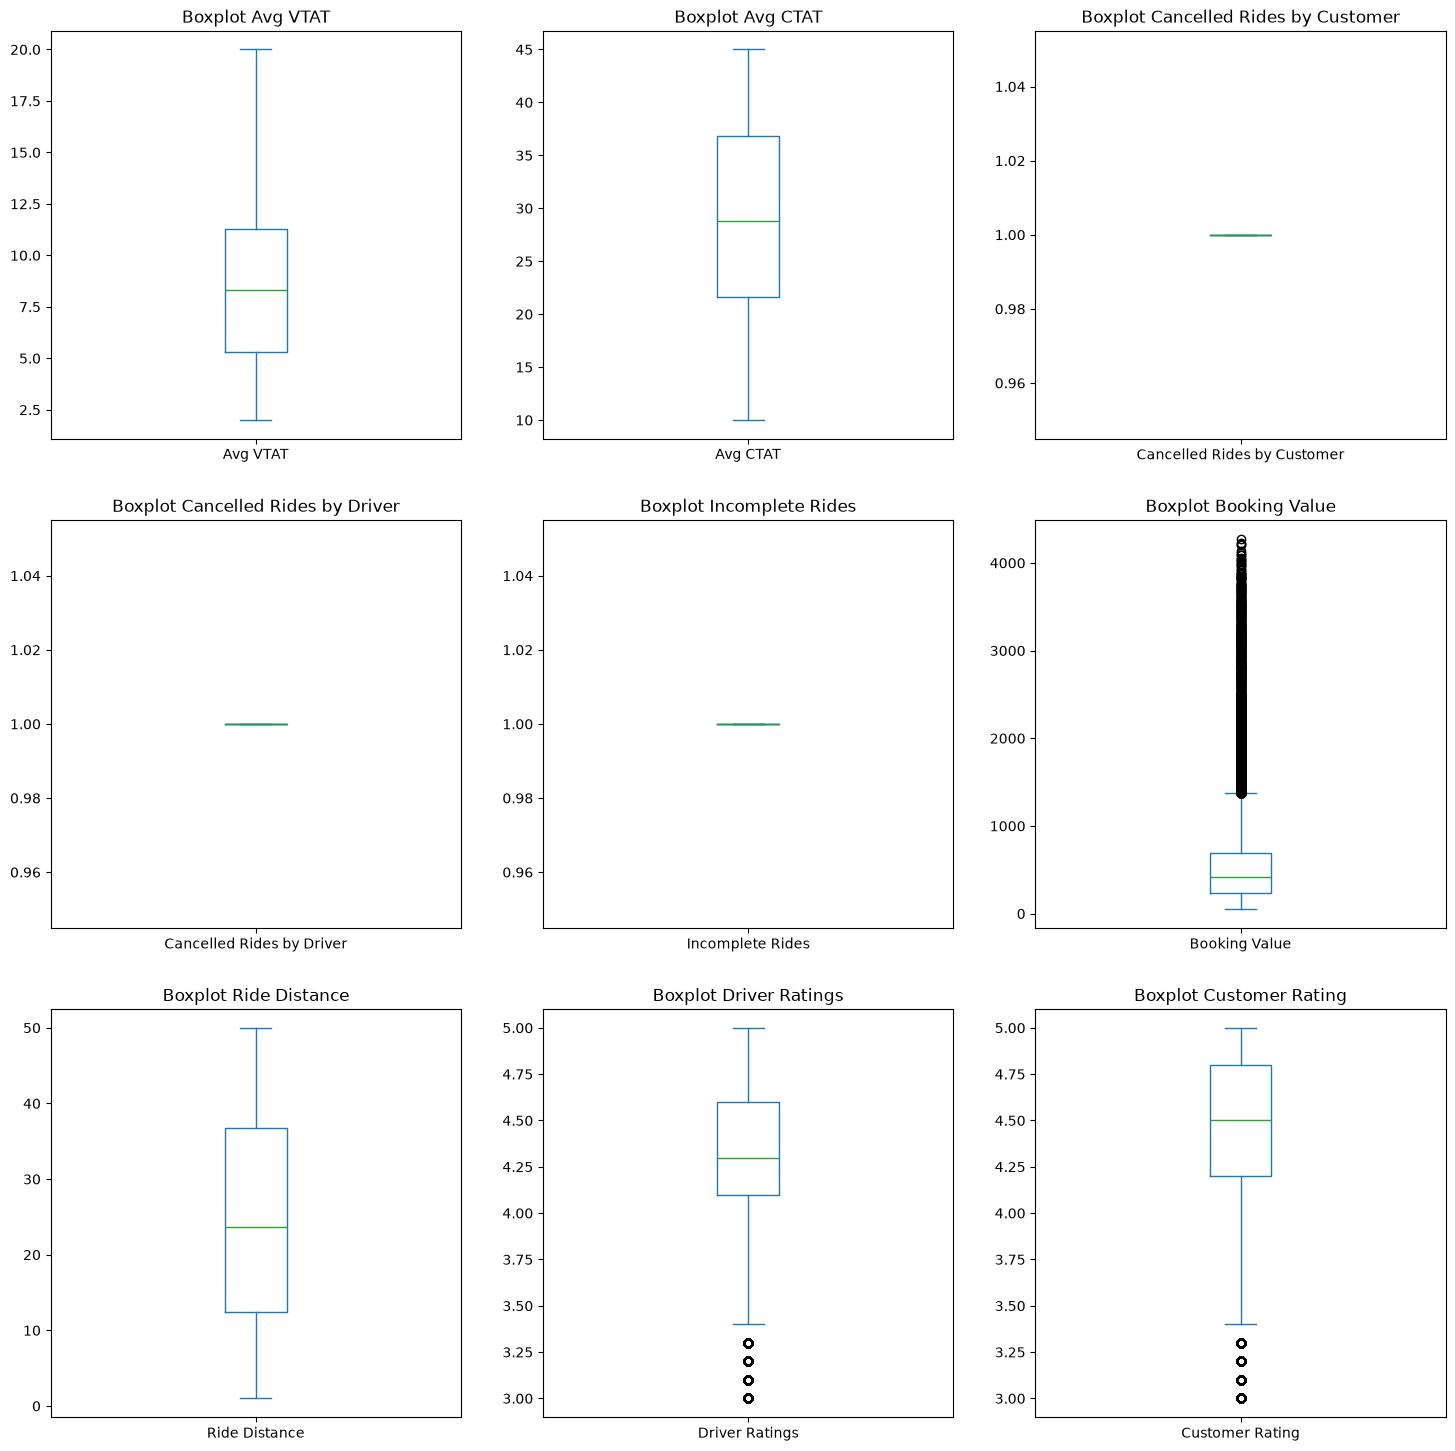

In [66]:
col_numerik = ['Avg VTAT', 'Avg CTAT', 'Cancelled Rides by Customer', 'Cancelled Rides by Driver', 'Incomplete Rides', 'Booking Value', 'Ride Distance', 'Driver Ratings', 'Customer Rating']
n_cols = 3
n_rows = math.ceil(len(col_numerik) / n_cols)
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, 6 * n_rows))
axes = axes.flatten()
for i, col in enumerate(col_numerik):
    df[col].plot(kind='box', ax=axes[i])
    axes[i].set_title(f'Boxplot {col}')

# Data Cleaning

In [67]:
df.drop_duplicates(subset=['Booking ID'], inplace=True)
df.shape

(148767, 21)

In [68]:
df['Avg VTAT'] = df['Avg VTAT'].fillna(df['Avg CTAT'].median()) # -> ambil median karena distribusi data cenderung tidak normal
df['Avg CTAT'] = df['Avg CTAT'].fillna(df['Avg CTAT'].median()) # -> ambil median karena distribusi data cenderung tidak normal
df['Cancelled Rides by Customer'] = df['Cancelled Rides by Customer'].fillna(0) # -> 1 = rides di canceled, 0 = rides tidak di canceled
df['Cancelled Rides by Driver'] = df['Cancelled Rides by Driver'].fillna(0) # -> 1 = rides di canceled, 0 = rides tidak di canceled
df['Incomplete Rides'] =  df['Incomplete Rides'].fillna(0) # -> 1 = incomplete, 0 = complete
df['Booking Value'] = df['Booking Value'].fillna(df['Booking Value'].median()) # -> ambil median karena distribusi data cenderung tidak normal
df['Ride Distance'] = df['Ride Distance'].fillna(df['Ride Distance'].median()) # -> ambil median karena distribusi data cenderung tidak normal
df['Driver Ratings'] = df['Driver Ratings'].fillna(df['Driver Ratings'].median()) # -> ambil median karena distribusi data cenderung tidak normal
df['Customer Rating'] = df['Customer Rating'].fillna(df['Customer Rating'].median()) # -> ambil median karena distribusi data cenderung tidak normal

df['Reason for cancelling by Customer'] = df['Reason for cancelling by Customer'].fillna("Unknown") # -> Null diberi "Unknown" karena tidak diketahui
df['Driver Cancellation Reason'] = df['Driver Cancellation Reason'].fillna("Unknown") # -> Null diberi "Unknown" karena tidak diketahui
df['Incomplete Rides Reason'] = df['Incomplete Rides Reason'].fillna('Unknown') # -> Null diberi "Unknown" karena tidak diketahui
df['Payment Method'] = df['Payment Method'].fillna('Unknown') # -> Null diberi "Unknown" karena tidak diketahui

In [70]:
df['Date'] = pd.to_datetime(df['Date'])

# Export Data

In [72]:
df.to_csv('clen_uber_dataset.csv', index=False)